# LAB 09 — Tokenizer and BIO Alignment

Notebook này thực hiện bài 16 và Experiment 1 (bài 17): xem cách CoNLL word được chia thành subword và kiểm tra label alignment theo Strategy A. Phần nhận xét cuối để sinh viên tự điền.

> **Run-order note:** saved experiment outputs were generated during an exploratory run before `prediction.md` was completed. They are real measurements, but must be rerun after the student writes predictions; the experiment cell now enforces that prerequisite.

## 1. Setup và reproducibility

In [ ]:
from pathlib import Path
import subprocess, sys
import json, platform
import pandas as pd
from IPython.display import display

# Notebook trên Colab chỉ được mở trực tiếp từ GitHub; runtime vẫn cần clone repo để có code và dữ liệu.
repo_url = "https://github.com/NguyenDucThang-tb/NLP.git"
repo_roots = [
    Path.cwd(),
    Path("/content/NLP/Lab9"),
    Path("/content/NLP/Lab09"),
    Path("/content/drive/MyDrive/NLP/Lab9"),
    Path("/content/drive/MyDrive/NLP/Lab09"),
]
LAB_DIR = next((p for p in repo_roots if (p / "ner_core.py").is_file()), None)

if LAB_DIR is None and Path("/content").exists():
    repo_dir = Path("/content/NLP")
    if not (repo_dir / "Lab9" / "ner_core.py").is_file():
        if repo_dir.exists():
            raise FileNotFoundError(
                f"Đã có {repo_dir} nhưng không thấy Lab9/ner_core.py. "
                "Xóa/đổi tên thư mục clone cũ hoặc clone repo vào thư mục khác."
            )
        subprocess.run(["git", "clone", "--depth", "1", repo_url, str(repo_dir)], check=True)
    LAB_DIR = repo_dir / "Lab9"

if LAB_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy Lab9/ner_core.py. Trong Colab, clone repository NLP trước "
        "hoặc đảm bảo toàn bộ thư mục Lab9 đã được push lên GitHub."
    )

sys.path.insert(0, str(LAB_DIR))
from ner_core import (
    DEFAULT_DATASET_ID, DEFAULT_MODEL_ID, IGNORE_INDEX,
    load_conll2003, dataset_summary, validate_bio_sequences,
    align_words, tokenization_statistics, seed_everything, prediction_ready
)
from experiment_tools import make_tokenization_rows, save_tokenization_outputs, write_environment_metadata

SEED = 42
DATASET_ID = DEFAULT_DATASET_ID
MODEL_ID = DEFAULT_MODEL_ID
OUTPUT_DIR = LAB_DIR / "outputs"
seed_everything(SEED)
print({"python": platform.python_version(), "dataset": DATASET_ID, "model": MODEL_ID, "seed": SEED})

## 2. Dataset inspection và BIO mapping

In [2]:
splits, label_names = load_conll2003(dataset_id=DATASET_ID)
label2id = {label: index for index, label in enumerate(label_names)}
id2label = {index: label for label, index in label2id.items()}

summary = pd.DataFrame(dataset_summary(splits))
display(summary)
print("label2id:", label2id)
print("Invalid BIO counts:", {name: len(validate_bio_sequences(split.labels)) for name, split in splits.items()})
assert set(splits) == {"train", "validation", "test"}
assert all(len(split.words) == len(split.labels) for split in splits.values())

,split,sentences,words,entity_counts,bio_label_counts,invalid_bio_sequences
0,train,14041,203618,"{'MISC': 3438, 'ORG': 6321, 'PER': 6600, 'LOC'...","{'B-ORG': 6321, 'O': 169575, 'B-MISC': 3438, '...",0
1,validation,3250,51360,"{'ORG': 1341, 'LOC': 1837, 'PER': 1842, 'MISC'...","{'O': 42757, 'B-ORG': 1341, 'B-LOC': 1837, 'B-...",0
2,test,3453,46427,"{'PER': 1617, 'LOC': 1668, 'MISC': 702, 'ORG':...","{'O': 38315, 'B-LOC': 1668, 'B-PER': 1617, 'I-...",0


label2id: {'O': 0, 'B-ORG': 1, 'B-MISC': 2, 'B-PER': 3, 'I-PER': 4, 'B-LOC': 5, 'I-ORG': 6, 'I-MISC': 7, 'I-LOC': 8}
Invalid BIO counts: {'train': 0, 'validation': 0, 'test': 0}


## 3. Fast tokenizer và word_ids

In [3]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
assert tokenizer.is_fast, "Cần fast tokenizer để gọi word_ids()"

example_words = splits["train"].words[0]
example_labels = splits["train"].labels[0]
raw_encoding = tokenizer(example_words, is_split_into_words=True, truncation=True, max_length=128)
example_word_ids = raw_encoding.word_ids()
example_alignment = align_words(example_words, example_labels, tokenizer, label2id, max_length=128)
print("Original words:", example_words)
print("Gold labels:", example_labels)
print("Subword tokens:", tokenizer.convert_ids_to_tokens(raw_encoding["input_ids"]))
print("input_ids:", raw_encoding["input_ids"])
print("attention_mask:", raw_encoding["attention_mask"])
print("word_ids:", example_word_ids)
print("Aligned label IDs:", example_alignment["aligned_labels"])
print("Aligned labels:", [id2label[x] if x != IGNORE_INDEX else "IGNORE" for x in example_alignment["aligned_labels"]])
print("Ignored positions:", sum(x == IGNORE_INDEX for x in example_alignment["aligned_labels"]))
print("Words split into subwords:", example_alignment["split_words"])

Original words: ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
Gold labels: ['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']
Subword tokens: ['[CLS]', 'EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'la', '##mb', '.', '[SEP]']
input_ids: [101, 7270, 22961, 1528, 1840, 1106, 21423, 1418, 2495, 12913, 119, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
word_ids: [None, 0, 1, 2, 3, 4, 5, 6, 7, 7, 8, None]
Aligned label IDs: [-100, 1, 0, 2, 0, 0, 0, 2, 0, -100, 0, -100]
Aligned labels: ['IGNORE', 'B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'IGNORE', 'O', 'IGNORE']
Ignored positions: 3
Words split into subwords: {7: 2}


# Formal Experiment 1 requires the student's own predictions first.
ready, reason = prediction_ready(LAB_DIR / "prediction.md")
if not ready:
    raise RuntimeError(f"Experiment 1 is gated: {reason}. Complete prediction.md before rerunning this section.")

token_rows, entity_comparison, split_words = make_tokenization_rows(splits["train"], tokenizer, count=20)
tokenization_table = pd.DataFrame(token_rows)
display(tokenization_table[["sentence_id", "length_group", "original_text", "word_count", "subword_token_count", "split_word_count", "split_ratio", "R"]])
display(pd.DataFrame(entity_comparison))
print("Average R:", tokenization_table["R"].mean())
print("Median R:", tokenization_table["R"].median())
print("Maximum R:", tokenization_table["R"].max())
print("Frequently split words:", split_words.most_common(20))

# Lưu bảng và biểu đồ đo từ tokenizer/câu CoNLL-2003.
save_tokenization_outputs(token_rows, entity_comparison, split_words, OUTPUT_DIR / "tokenization")
write_environment_metadata(OUTPUT_DIR / "environment.json", DATASET_ID, splits, MODEL_ID, SEED)

## 4. Experiment 1 — Tokenization analysis (ít nhất 20 câu)

In [4]:
token_rows, entity_comparison, split_words = make_tokenization_rows(splits["train"], tokenizer, count=20)
tokenization_table = pd.DataFrame(token_rows)
display(tokenization_table[["sentence_id", "length_group", "original_text", "word_count", "subword_token_count", "split_word_count", "split_ratio", "R"]])
display(pd.DataFrame(entity_comparison))
print("Average R:", tokenization_table["R"].mean())
print("Median R:", tokenization_table["R"].median())
print("Maximum R:", tokenization_table["R"].max())
print("Frequently split words:", split_words.most_common(20))

# Lưu bảng/biểu đồ đo được từ tokenizer và câu CoNLL-2003 thật.
save_tokenization_outputs(token_rows, entity_comparison, split_words, OUTPUT_DIR / "tokenization")
write_environment_metadata(OUTPUT_DIR / "environment.json", DATASET_ID, splits, MODEL_ID, SEED)

,sentence_id,length_group,original_text,word_count,subword_token_count,split_word_count,split_ratio,R
0,82,short,LAST S&P AA+ REOFFER =,5,13,4,0.800000,2.600000
1,83,short,NOTES S SHORT FIRST COUPON,5,13,4,0.800000,2.600000
2,88,short,NOTES ISSUED OFF EMTN PROGRAMME,5,16,5,1.000000,3.200000
3,181,short,He did not elaborate .,5,5,0,0.000000,1.000000
4,245,short,Summary of Consolidated Financial Data,5,7,1,0.200000,1.400000
5,247,short,Six Months Ended Quarter Ended,5,8,3,0.600000,1.600000
6,290,short,"Imports 10,663 10,725 43,430 40,989",5,18,5,1.000000,3.600000
7,291,short,"Exports 14,494 14,153 56,126 56,261",5,15,5,1.000000,3.000000
8,292,short,"Balance +3,831 +3,428 +12,696 +15,272",5,21,5,1.000000,4.200000
9,322,short,Scores from the $ 2.1,5,8,2,0.400000,1.600000


,word_group,word_count,split_word_count,mean_subwords_per_word,split_ratio
0,entity,113,37,1.539823,0.327434
1,non-entity,615,126,1.414634,0.204878


Average R: 1.915350696194024
Median R: 1.556637168141593
Maximum R: 4.2
Frequently split words: [('-LPR-', 11), ('-RPR-', 11), ('nil', 6), ('NOTES', 2), ('Ended', 2), ('--', 2), ("'s", 2), ('2p', 2), ('bales', 2), ('LAST', 1), ('S&P', 1), ('AA+', 1), ('REOFFER', 1), ('SHORT', 1), ('FIRST', 1), ('COUPON', 1), ('ISSUED', 1), ('OFF', 1), ('EMTN', 1), ('PROGRAMME', 1)]


{'dataset_source': 'tner/conll2003',
 'dataset_license_note': 'See the CoNLL-2003 dataset card and original Reuters data terms.',
 'split_sizes_sentences': {'train': 14041, 'validation': 3250, 'test': 3453},
 'split_sizes_words': {'train': 203618, 'validation': 51360, 'test': 46427},
 'base_model': 'distilbert/distilbert-base-cased',
 'random_seed': 42,
 'python': '3.12.3',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'packages': {'torch': '2.15.0',
  'transformers': '5.23.0',
  'datasets': '4.8.5',
  'accelerate': '1.16.0',
  'scikit-learn': '1.9.1',
  'seqeval': '1.2.2',
  'numpy': '2.5.5',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2'},
 'cuda_available': False,
 'gpu': None}

## 5. Visualization

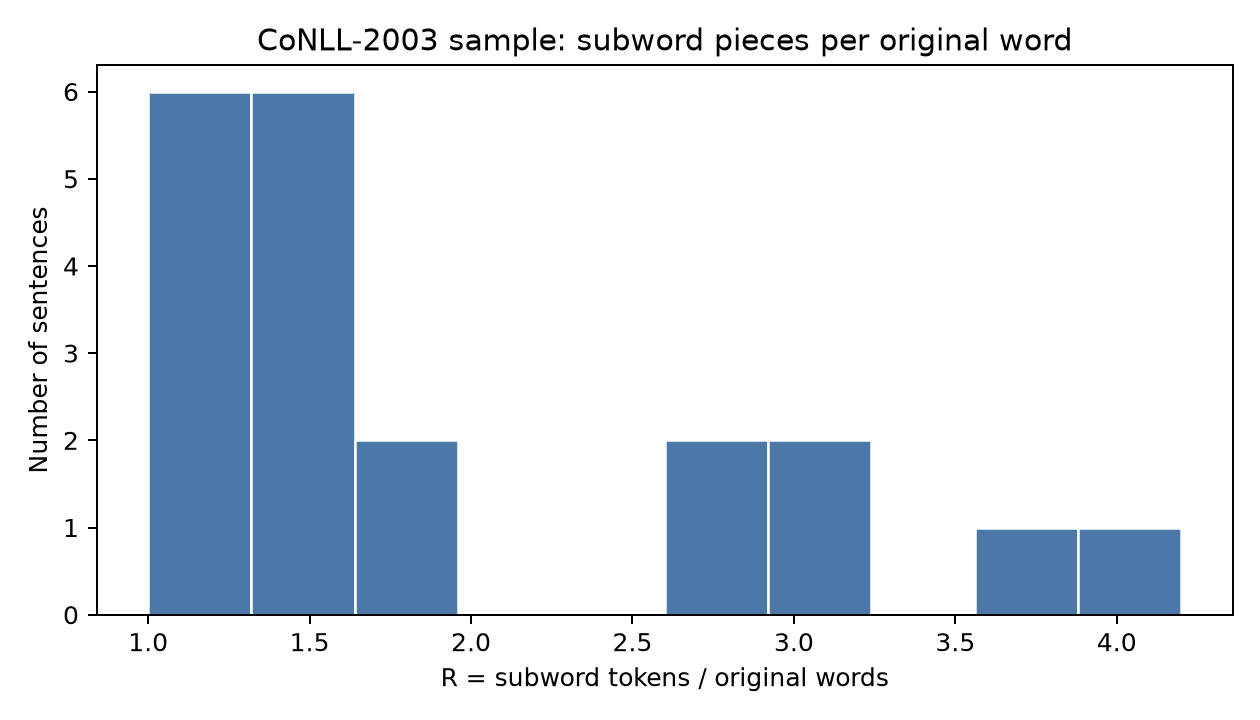

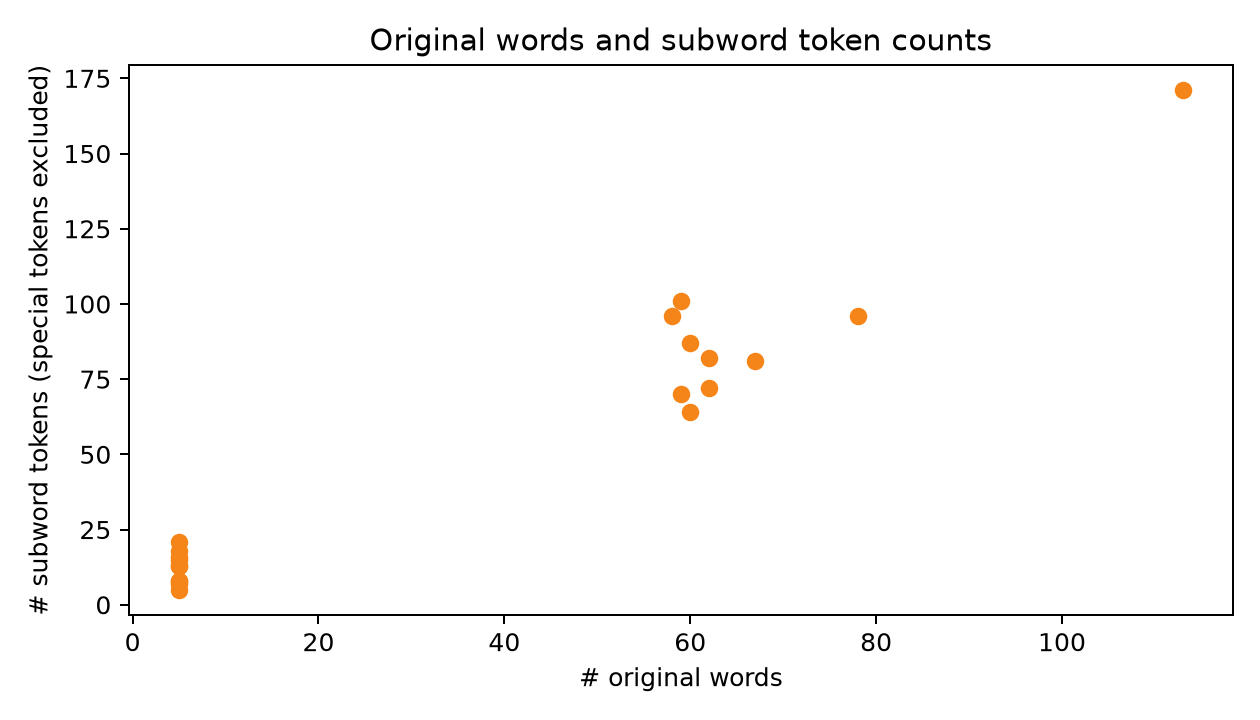

In [5]:
from IPython.display import Image, display
for filename in ["tokenization_ratio.png", "words_vs_subwords.png"]:
    path = OUTPUT_DIR / "tokenization" / filename
    if path.exists(): display(Image(filename=str(path)))

## 6. Interpretation — sinh viên tự hoàn thành

- Từ loại nào trong bảng thường bị chia thành nhiều subword? Dẫn chứng bằng các từ cụ thể.
- `R` khác nhau thế nào giữa câu ngắn và câu dài trong mẫu đã chọn?
- Tỷ lệ split của entity words khác non-entity words ra sao?
- Những giới hạn nào có thể ảnh hưởng đến kết quả tokenization này?

**Student analysis:** TODO — tự viết dựa trên các bảng và biểu đồ vừa chạy.